In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost.sklearn import XGBClassifier

In [ ]:
import pandas as pd
df = pd.read_csv('/content/loan-test.csv')

In [ ]:
import pandas as pd
train = pd.read_csv('/content/loan-test.csv')
test = pd.read_csv('/content/loan-test.csv')
train.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban


In [ ]:
train.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [ ]:
#STEP 1: Data Pre- Processing

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1228 entries, 0 to 1227
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            1228 non-null   object 
 1   Gender             1202 non-null   object 
 2   Married            1222 non-null   object 
 3   Dependents         1198 non-null   object 
 4   Education          1228 non-null   object 
 5   Self_Employed      1164 non-null   object 
 6   ApplicantIncome    1228 non-null   int64  
 7   CoapplicantIncome  1228 non-null   float64
 8   LoanAmount         1184 non-null   float64
 9   Loan_Amount_Term   1200 non-null   float64
 10  Credit_History     1128 non-null   float64
 11  Property_Area      1228 non-null   object 
 12  Loan_Status        1228 non-null   object 
 13  source             1228 non-null   object 
dtypes: float64(4), int64(1), object(9)
memory usage: 134.4+ KB


In [ ]:
dataset.isnull().sum()

,0
Loan_ID,0
Gender,26
Married,6
Dependents,30
Education,0
Self_Employed,64
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,44
Loan_Amount_Term,28


In [ ]:
print(dataset['Gender'].unique())
print(dataset['Married'].unique())
print(dataset['Dependents'].unique())
print(dataset['Self_Employed'].unique())
print(dataset['LoanAmount'].unique())
print(dataset['Loan_Amount_Term'].unique())
print(dataset['Credit_History'].unique())

['Male' 'Female' nan]
['No' 'Yes' nan]
['0' '1' '2' '3+' nan]
['No' 'Yes' nan]
[ nan 128.  66. 120. 141. 267.  95. 158. 168. 349.  70. 109. 200. 114.
  17. 125. 100.  76. 133. 115. 104. 315. 116. 112. 151. 191. 122. 110.
  35. 201.  74. 106. 320. 144. 184.  80.  47.  75. 134.  96.  88.  44.
 286.  97. 135. 180.  99. 165. 258. 126. 312. 136. 172.  81. 187. 113.
 176. 130. 111. 167. 265.  50. 210. 175. 131. 188.  25. 137. 160. 225.
 216.  94. 139. 152. 118. 185. 154.  85. 259. 194.  93. 370. 182. 650.
 102. 290.  84. 242. 129.  30. 244. 600. 255.  98. 275. 121.  63. 700.
  87. 101. 495.  67.  73. 260. 108.  58.  48. 164. 170.  83.  90. 166.
 124.  55.  59. 127. 214. 240.  72.  60. 138.  42. 280. 140. 155. 123.
 279. 192. 304. 330. 150. 207. 436.  78.  54.  89. 143. 105. 132. 480.
  56. 159. 300. 376. 117.  71. 490. 173.  46. 228. 308. 236. 570. 380.
 296. 156. 103.  45.  65.  53. 360.  62. 218. 178. 239. 405. 148. 190.
 149. 153. 162. 230.  86. 234. 246. 500. 186. 119. 107. 209. 208. 243

In [ ]:
# replacing missing data with substituted values

In [ ]:
dataset['Gender'].fillna(dataset['Gender'].mode()[0], inplace=True)
dataset['Married'].fillna(dataset['Married'].mode()[0], inplace=True)
dataset['Dependents'].fillna(dataset['Dependents'].mode()[0], inplace=True)
dataset['Self_Employed'].fillna(dataset['Self_Employed'].mode()[0], inplace=True)
dataset['LoanAmount'].fillna(dataset['LoanAmount'].median(), inplace=True)
dataset['Loan_Amount_Term'].fillna(dataset['Loan_Amount_Term'].median(), inplace=True)
dataset['Credit_History'].fillna(dataset['Credit_History'].mode()[0], inplace=True)

/tmp/ipython-input-32314181.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['Gender'].fillna(dataset['Gender'].mode()[0], inplace=True)
/tmp/ipython-input-32314181.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace

In [ ]:
dataset.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1228 entries, 0 to 1227
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            1228 non-null   object 
 1   Gender             1228 non-null   object 
 2   Married            1228 non-null   object 
 3   Dependents         1228 non-null   object 
 4   Education          1228 non-null   object 
 5   Self_Employed      1228 non-null   object 
 6   ApplicantIncome    1228 non-null   int64  
 7   CoapplicantIncome  1228 non-null   float64
 8   LoanAmount         1228 non-null   float64
 9   Loan_Amount_Term   1228 non-null   float64
 10  Credit_History     1228 non-null   float64
 11  Property_Area      1228 non-null   object 
 12  Loan_Status        1228 non-null   object 
 13  source             1228 non-null   object 
dtypes: float64(4), int64(1), object(9)
memory usage: 134.4+ KB


In [ ]:
print(len(dataset['Gender'].unique()))
print(len(dataset['Married'].unique()))
print(len(dataset['Dependents'].unique()))
print(len(dataset['Self_Employed'].unique()))
print(len(dataset['LoanAmount'].unique()))
print(len(dataset['Loan_Amount_Term'].unique()))
print(len(dataset['Credit_History'].unique()))
print(len(dataset['Loan_ID'].unique()))
print(len(dataset['Education'].unique()))
print(len(dataset['ApplicantIncome'].unique()))
print(len(dataset['CoapplicantIncome'].unique()))
print(len(dataset['Property_Area'].unique()))
print(len(dataset['source'].unique()))

2
2
4
2
203
10
2
614
2
505
287
3
2


In [ ]:
#Spliting the train and test set again after replacing all missing values

In [ ]:
#Divide into test and train:
train = dataset.loc[dataset['source']=="train"]
test = dataset.loc[dataset['source']=="test"]
#Drop unnecessary columns:
test.drop(['source'],axis=1,inplace=True)
train.drop(['source'],axis=1,inplace=True)

/tmp/ipython-input-2114946786.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test.drop(['source'],axis=1,inplace=True)
/tmp/ipython-input-2114946786.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train.drop(['source'],axis=1,inplace=True)


In [ ]:
train.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [ ]:
#Step 2: Data Visualization

<Axes: title={'center': 'Loan Status Bar Plot'}, xlabel='Loan_Status', ylabel='Loan Status Count'>

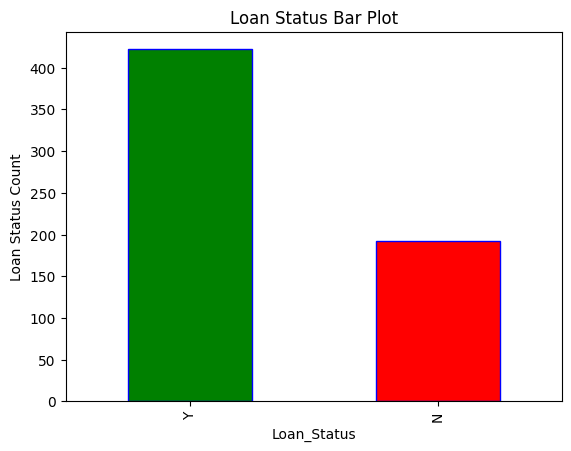

In [ ]:
plt.title('Loan Status Bar Plot')
plt.xlabel('Loan Status Y - Yes or N- No')
plt.ylabel('Loan Status Count')

train['Loan_Status'].value_counts().plot.bar(color=['green', 'red'],edgecolor='blue')

<Axes: title={'center': 'Credit History'}, xlabel='Credit_History'>

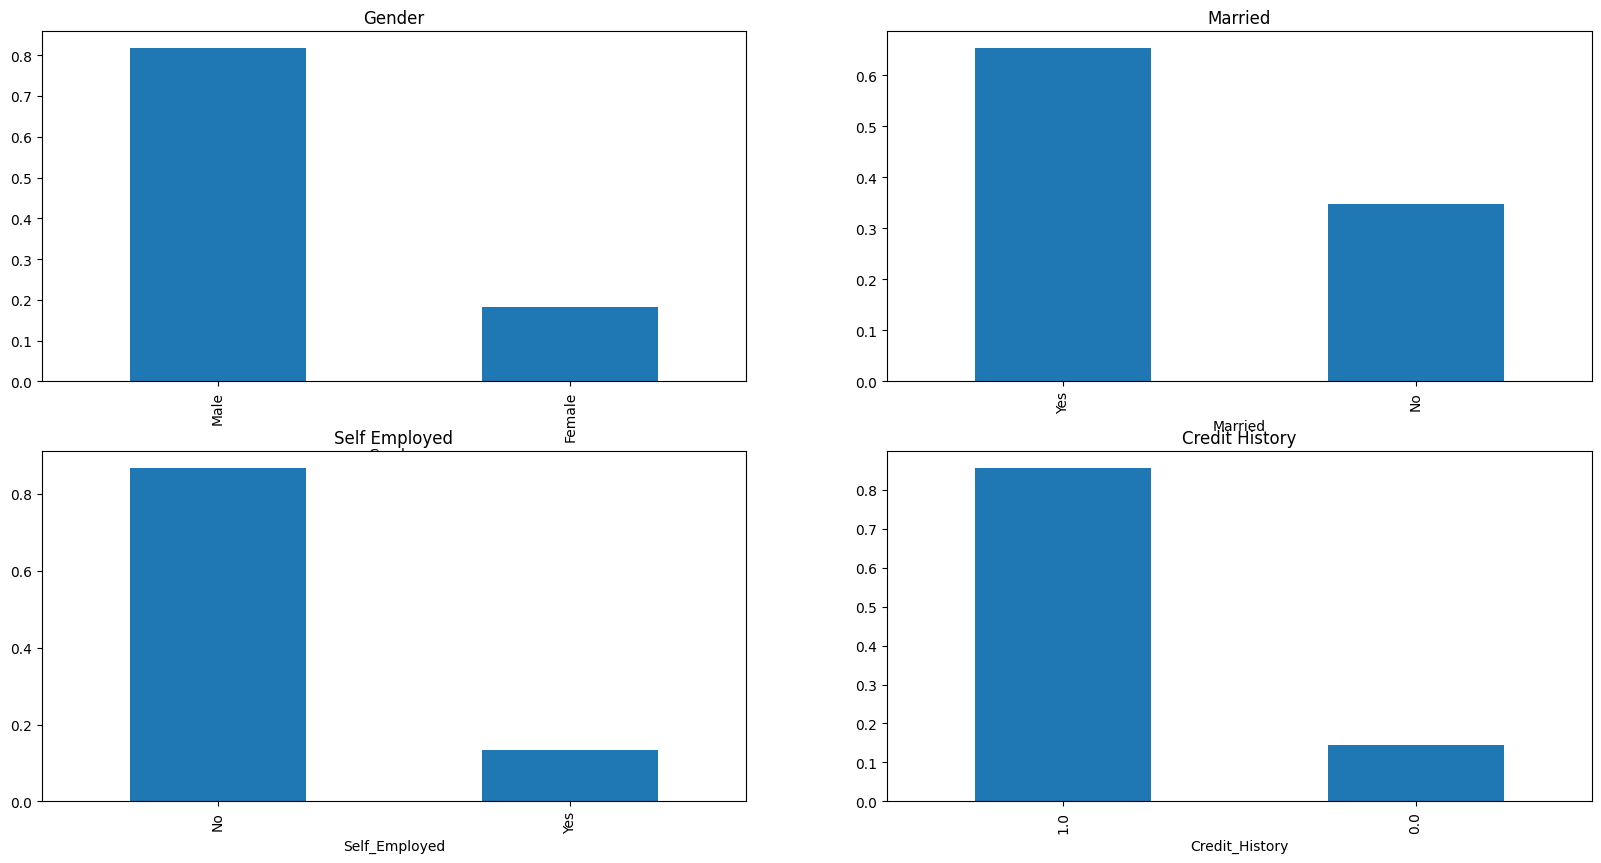

In [ ]:
plt.figure(figsize=(20,10))
plt.subplot(2,2,1)
train['Gender'].value_counts(normalize=True).plot.bar(title='Gender')
plt.subplot(2,2,2)
train['Married'].value_counts(normalize=True).plot.bar(title='Married')
plt.subplot(2,2,3)
train['Self_Employed'].value_counts(normalize=True).plot.bar(title='Self Employed')
plt.subplot(2,2,4)
train['Credit_History'].value_counts(normalize=True).plot.bar(title='Credit History')

<Axes: xlabel='Property_Area'>

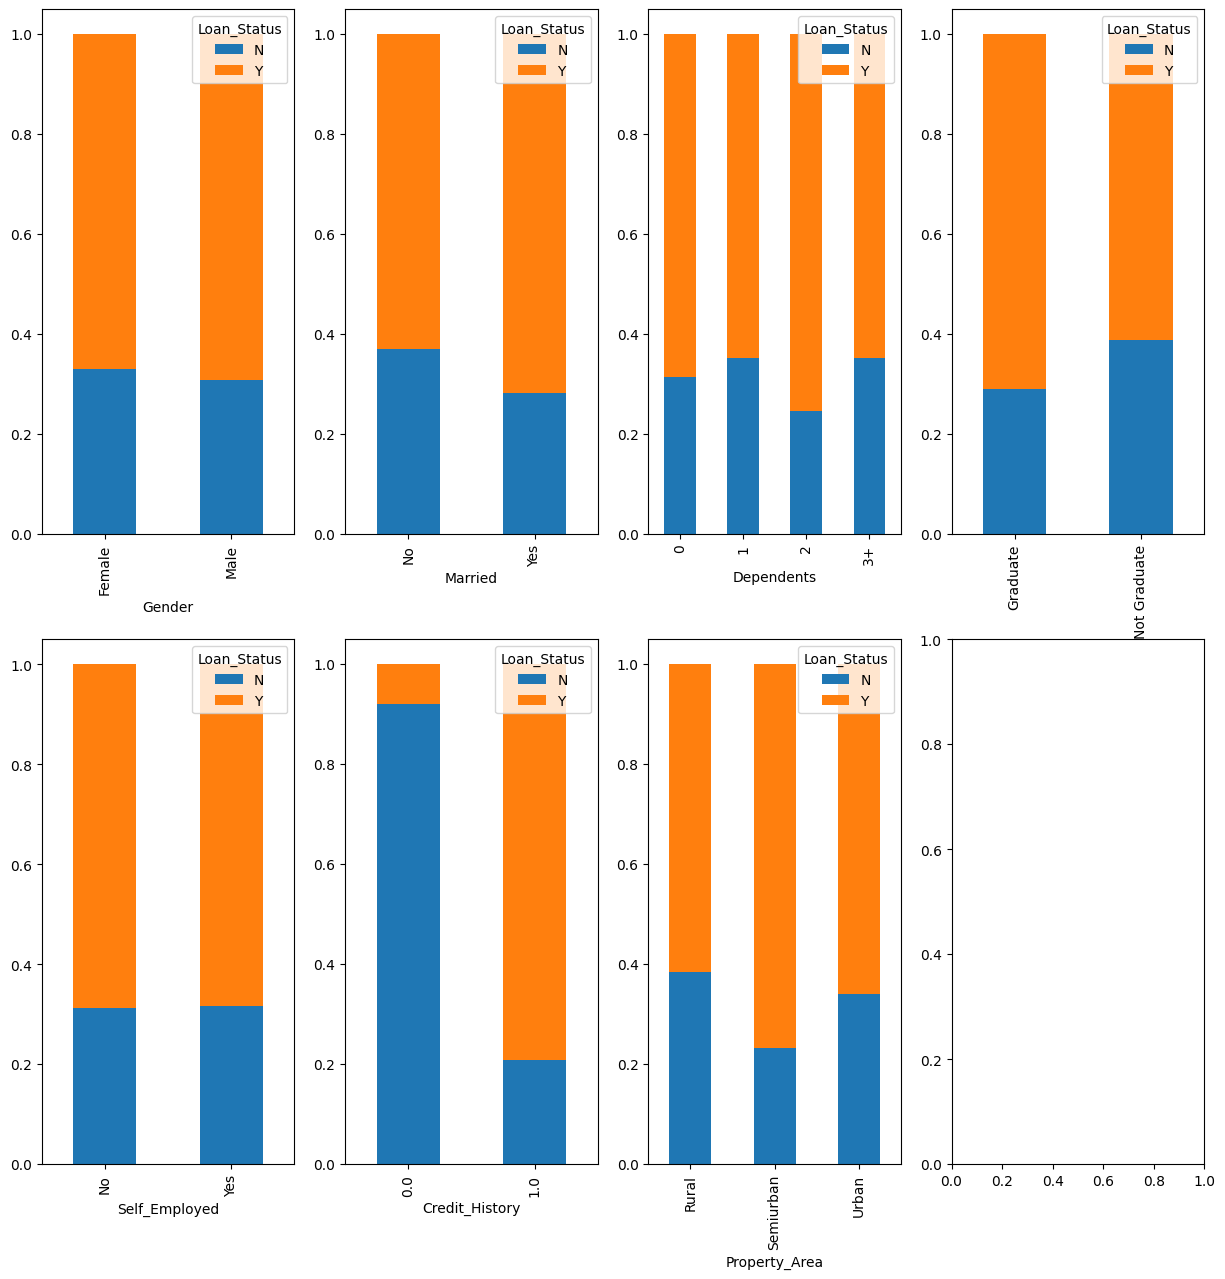

In [ ]:
fig, ax = plt.subplots(2,4,figsize = (15,15))
Gender = pd.crosstab(train['Gender'],train['Loan_Status'])
Gender.div(Gender.sum(1).astype(float), axis=0).plot(kind="bar", stacked=True, ax=ax[0,0])

Married = pd.crosstab(train['Married'],train['Loan_Status'])
Married.div(Married.sum(1).astype(float),axis=0).plot(kind='bar',stacked=True, ax=ax[0,1])

Dependents = pd.crosstab(train['Dependents'],train['Loan_Status'])
Dependents.div(Dependents.sum(1).astype(float),axis=0).plot(kind='bar',stacked=True, ax=ax[0,2])

Education = pd.crosstab(train['Education'],train['Loan_Status'])
Education.div(Education.sum(1).astype(float),axis=0).plot(kind='bar',stacked=True,ax=ax[0,3])

Self_Employed = pd.crosstab(train['Self_Employed'],train['Loan_Status'])
Self_Employed.div(Self_Employed.sum(1).astype(float),axis=0).plot(kind='bar',stacked=True, ax=ax[1,0])

Credit_History = pd.crosstab(train['Credit_History'],train['Loan_Status'])
Credit_History.div(Credit_History.sum(1).astype(float),axis=0).plot(kind='bar',stacked=True, ax=ax[1,1])

Property_Area = pd.crosstab(train['Property_Area'],train['Loan_Status'])
Property_Area.div(Property_Area.sum(1).astype(float),axis=0).plot(kind='bar',stacked=True,ax=ax[1,2])

In [ ]:
#STEP 3 : Converting the categorical data into numerical data appropriately¶

In [ ]:
#cols=['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education','Self_Employed','Property_Area']
#for label in cols:
#    dataset[label]=LabelEncoder().fit_transform(dataset[label])
#dataset.head()

In [ ]:
X=train.drop(["Loan_Status",'Loan_ID'],axis=1)
y=train["Loan_Status"]

X = pd.get_dummies(X,drop_first=True)
X.head()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,5849,0.0,128.0,360.0,1.0,True,False,False,False,False,False,False,False,True
1,4583,1508.0,128.0,360.0,1.0,True,True,True,False,False,False,False,False,False
2,3000,0.0,66.0,360.0,1.0,True,True,False,False,False,False,True,False,True
3,2583,2358.0,120.0,360.0,1.0,True,True,False,False,False,True,False,False,True
4,6000,0.0,141.0,360.0,1.0,True,False,False,False,False,False,False,False,True


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=0)

In [ ]:
#Fitting the dataset to various models

In [ ]:
#Logistic Regression

In [ ]:
logistic_Regression = LogisticRegression(max_iter=1000,random_state=0)
logistic_Regression.fit(x_train,y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, random_state=0)

In [ ]:
y_pred = logistic_Regression.predict(x_test)

In [ ]:
log = accuracy_score(y_pred,y_test)*100

In [ ]:
print(confusion_matrix(y_pred,y_test))

[[ 22   2]
 [ 29 132]]


In [ ]:
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

           N       0.43      0.92      0.59        24
           Y       0.99      0.82      0.89       161

    accuracy                           0.83       185
   macro avg       0.71      0.87      0.74       185
weighted avg       0.91      0.83      0.85       185



In [ ]:
#KNN

In [ ]:
knn = KNeighborsClassifier(n_neighbors=200)
knn.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=200)

In [ ]:
pred_knn = knn.predict(x_test)

In [ ]:
KNN = accuracy_score(pred_knn,y_test)*100

In [ ]:
print(confusion_matrix(pred_knn,y_test))

[[  0   0]
 [ 51 134]]


In [ ]:
print(classification_report(pred_knn,y_test))

              precision    recall  f1-score   support

           N       0.00      0.00      0.00         0
           Y       1.00      0.72      0.84       185

    accuracy                           0.72       185
   macro avg       0.50      0.36      0.42       185
weighted avg       1.00      0.72      0.84       185



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
error=[]
for i in range(1,50):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train,y_train)
    pred1=knn.predict(x_test)
    error.append(np.mean(pred1!=y_test))
print(error)

[np.float64(0.43243243243243246), np.float64(0.4864864864864865), np.float64(0.40540540540540543), np.float64(0.42162162162162165), np.float64(0.372972972972973), np.float64(0.3891891891891892), np.float64(0.3675675675675676), np.float64(0.372972972972973), np.float64(0.31891891891891894), np.float64(0.35135135135135137), np.float64(0.3081081081081081), np.float64(0.34594594594594597), np.float64(0.32432432432432434), np.float64(0.33513513513513515), np.float64(0.32432432432432434), np.float64(0.31351351351351353), np.float64(0.2972972972972973), np.float64(0.32972972972972975), np.float64(0.3027027027027027), np.float64(0.31351351351351353), np.float64(0.2972972972972973), np.float64(0.31351351351351353), np.float64(0.2972972972972973), np.float64(0.2972972972972973), np.float64(0.2864864864864865), np.float64(0.2918918918918919), np.float64(0.2810810810810811), np.float64(0.2864864864864865), np.float64(0.2810810810810811), np.float64(0.2810810810810811), np.float64(0.281081081081081

Text(0, 0.5, 'error rate')

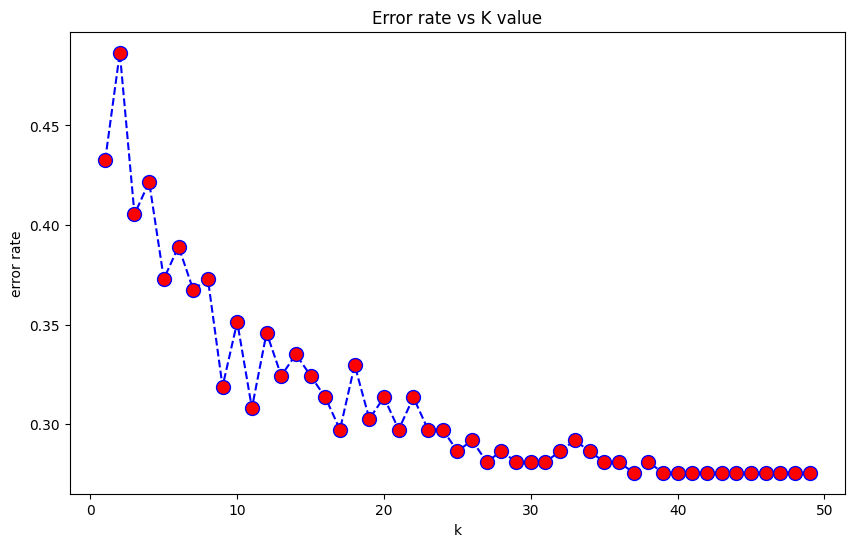

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(range(1,50),error,color='blue',linestyle='dashed',marker = 'o',markerfacecolor='red',markersize=10)
plt.title('Error rate vs K value')
plt.xlabel('k')
plt.ylabel('error rate')

In [ ]:
#Naive-Bayes

In [ ]:
gnb=GaussianNB()
gnb.fit(x_train,y_train)

GaussianNB()

In [ ]:
pred_gnb = gnb.predict(x_test)

In [ ]:
GNB = accuracy_score(pred_gnb,y_test)*100

In [ ]:
print(confusion_matrix(pred_gnb,y_test))

[[ 22   4]
 [ 29 130]]


In [ ]:
print(classification_report(pred_gnb,y_test))

              precision    recall  f1-score   support

           N       0.43      0.85      0.57        26
           Y       0.97      0.82      0.89       159

    accuracy                           0.82       185
   macro avg       0.70      0.83      0.73       185
weighted avg       0.89      0.82      0.84       185



In [ ]:
#SVM

In [ ]:
svc = SVC()
svc.fit(x_train,y_train)
pred_svc = svc.predict(x_test)

In [ ]:
SVC = accuracy_score(pred_svc,y_test)*100

In [ ]:
print(confusion_matrix(pred_svc,y_test))

[[  0   0]
 [ 51 134]]


In [ ]:
print(classification_report(pred_svc,y_test))

              precision    recall  f1-score   support

           N       0.00      0.00      0.00         0
           Y       1.00      0.72      0.84       185

    accuracy                           0.72       185
   macro avg       0.50      0.36      0.42       185
weighted avg       1.00      0.72      0.84       185



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
#Decision Tree - Entropy

In [ ]:
dtree_en = DecisionTreeClassifier(criterion='entropy',splitter='random',max_leaf_nodes=5,min_samples_leaf=10,max_depth=3)

In [ ]:
clf = dtree_en.fit(x_train,y_train)

In [ ]:
pred_dt = clf.predict(x_test)

In [ ]:
DTREE = accuracy_score(pred_dt,y_test)*100

In [ ]:
cm=confusion_matrix(y_test,pred_dt)
print(cm)
print(classification_report(y_test,pred_dt))

[[ 21  30]
 [  2 132]]
              precision    recall  f1-score   support

           N       0.91      0.41      0.57        51
           Y       0.81      0.99      0.89       134

    accuracy                           0.83       185
   macro avg       0.86      0.70      0.73       185
weighted avg       0.84      0.83      0.80       185



In [ ]:
#Decision Tree - Gini

In [ ]:
dtree = DecisionTreeClassifier(criterion='gini',splitter='random',max_leaf_nodes=5,min_samples_leaf=10,max_depth=5)
dtree.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=5, max_leaf_nodes=5, min_samples_leaf=10,
                       splitter='random')

In [ ]:
pred_g = dtree.predict(x_test)

In [ ]:
DTREE_G = accuracy_score(y_test,pred_g)*100

In [ ]:
cm=confusion_matrix(y_test,pred_g)
print(cm)
print(classification_report(y_test,pred_g))

[[ 21  30]
 [  2 132]]
              precision    recall  f1-score   support

           N       0.91      0.41      0.57        51
           Y       0.81      0.99      0.89       134

    accuracy                           0.83       185
   macro avg       0.86      0.70      0.73       185
weighted avg       0.84      0.83      0.80       185



In [ ]:
#Random Forest

In [ ]:
rfc = RandomForestClassifier(criterion='entropy',n_estimators=400)
rfc.fit(x_train, y_train)

RandomForestClassifier(criterion='entropy', n_estimators=400)

In [ ]:
pred_rf= rfc.predict(x_test)

In [ ]:
RFC = accuracy_score(y_test,pred_rf)*100
RFC

80.0

In [ ]:
RFC = accuracy_score(y_test,pred_rf)*100
RFC

80.0

In [ ]:
print(confusion_matrix(pred_rf,y_test))

[[ 22   8]
 [ 29 126]]


In [ ]:
print(classification_report(pred_rf,y_test))

              precision    recall  f1-score   support

           N       0.43      0.73      0.54        30
           Y       0.94      0.81      0.87       155

    accuracy                           0.80       185
   macro avg       0.69      0.77      0.71       185
weighted avg       0.86      0.80      0.82       185



In [ ]:
 #AdaBoost (Entropy-Decision Tree)

In [ ]:
model = DecisionTreeClassifier(criterion='entropy',max_depth=1,random_state=0)
adaboost = AdaBoostClassifier(n_estimators=80, estimator=model,random_state=0)
adaboost.fit(x_train,y_train)

AdaBoostClassifier(estimator=DecisionTreeClassifier(criterion='entropy',
                                                    max_depth=1,
                                                    random_state=0),
                   n_estimators=80, random_state=0)

In [ ]:
pred = adaboost.predict(x_test)

In [ ]:
ada = accuracy_score(y_test,pred)*100

In [ ]:
 #AdaBoost (Gini-Decision Tree)

In [ ]:
model_g = DecisionTreeClassifier(criterion='gini',max_depth=1,random_state=0)
adaboost1 = AdaBoostClassifier(n_estimators=90, estimator=model_g,random_state=0)
adaboost1.fit(x_train,y_train)

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1,
                                                    random_state=0),
                   n_estimators=90, random_state=0)

In [ ]:
pred_gini = adaboost.predict(x_test)

In [ ]:
g = accuracy_score(y_test,pred_gini)*100

In [ ]:
#XGBoosT

In [ ]:
xgb =  XGBClassifier(learning_rate =0.000001,n_estimators=1000,max_depth=5,min_child_weight=1,subsample=0.8,colsample_bytree=0.8,nthread=4,scale_pos_weight=1,seed=27)

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

xgb.fit(x_train, y_train_encoded)
predxg = xgb.predict(x_test)
xg = accuracy_score(y_test_encoded,predxg)*100

In [ ]:
print("1)  Logistic Regression    :",log)
print("2)  AdaBoost - Entropy     :",ada)
print("3)  AdaBoost - Gini        :",g)
print("4)  XGBoost                :",xg)
print("5)  Decision Tree - Entropy:",DTREE)
print("6)  Decision Tree - Gini   :",DTREE_G)
print("7)  Random Forest          :",RFC)
print("8)  Naive-Bayes            :",GNB)
print("9)  KNN                    :",KNN)
print("10) SVC                    :",SVC)

1)  Logistic Regression    : 83.24324324324324
2)  AdaBoost - Entropy     : 82.70270270270271
3)  AdaBoost - Gini        : 82.70270270270271
4)  XGBoost                : 72.43243243243244
5)  Decision Tree - Entropy: 82.70270270270271
6)  Decision Tree - Gini   : 82.70270270270271
7)  Random Forest          : 80.0
8)  Naive-Bayes            : 82.16216216216216
9)  KNN                    : 72.43243243243244
10) SVC                    : 72.43243243243244


In [ ]:
#Step 5: Deciding Best Fit Model

#1)  Logistic Regression    : 83.78 %

2)  XGBoost                : 82.70 %

3)  Decision Tree - Entropy: 82.70 %

4)  Decision Tree - Gini   : 82.70 %

5)  Naive-Bayes            : 82.16 %

6)  AdaBoost - Entropy     : 81.62 %

7)  AdaBoost - Gini        : 81.62 %

8)  Random Forest          : 78.37 %

9)  KNN                    : 72.43 %

10) SVC                    : 72.43 %

In [ ]:
#STEP 6: Predicting the values of Loan_Status for the data given in test_lAUu6dG.csv

In [ ]:
Xt = test.drop(["Loan_ID"],axis=1)
Xt = pd.get_dummies(Xt,drop_first=True)

Xt.head()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,5720,0,110.0,360.0,1.0,True,True,False,False,False,False,False,False,True
1,3076,1500,126.0,360.0,1.0,True,True,True,False,False,False,False,False,True
2,5000,1800,208.0,360.0,1.0,True,True,False,True,False,False,False,False,True
3,2340,2546,100.0,360.0,NaN,True,True,False,True,False,False,False,False,True
4,3276,0,78.0,360.0,1.0,True,False,False,False,False,True,False,False,True


In [ ]:
#Applying the Logistic Regression Model to the test datase

In [ ]:
Xt = test.drop(["Loan_ID"],axis=1)
Xt = pd.get_dummies(Xt,drop_first=True)
Xt.head()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,5720,0,110.0,360.0,1.0,True,True,False,False,False,False,False,False,True
1,3076,1500,126.0,360.0,1.0,True,True,True,False,False,False,False,False,True
2,5000,1800,208.0,360.0,1.0,True,True,False,True,False,False,False,False,True
3,2340,2546,100.0,360.0,NaN,True,True,False,True,False,False,False,False,True
4,3276,0,78.0,360.0,1.0,True,False,False,False,False,True,False,False,True
